# Parte 6 (opcional, 2 puntos extra): ¿Le gana una regresión logística al BG/NBD?

En la Parte 4 vimos que el BG/NBD no ordena a los clientes mucho mejor que la recencia sola.
Si lo que queremos es $\mathbb{P}(Z=1)$, ¿para qué tanto esfuerzo con estos modelos?

Una regresión logística con $x$, $t_x$ y $T$ como predictores es la respuesta obvia de cualquier
científico de datos. Aquí la ponemos a competir y después revisamos si la competencia fue justa.

## 6.1 La comparación ingenua

Ajustamos una regresión logística de $Z_i$ contra $x$, $t_x$ y $T$ (estandarizados, sin penalización),
la evaluamos con validación cruzada estratificada de 5 *folds* **sobre clientes**, repetida con 20 semillas,
y la comparamos contra el $\mathbb{P}(Z=1)$ del BG/NBD del inciso 4.3 en AUC, *Brier score* y curva de calibración.

In [1]:
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss

from src.data_prep import cargar_transacciones, construir_resumen

# Colores: una serie = un color fijo, el mismo en todas las graficas
C_BG, C_LOG, C_GRIS = "#2563eb", "#ea580c", "#9ca3af"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "font.size": 10,
})

In [2]:
df = cargar_transacciones("../data/raw/CDNOW_sample.txt")
res = construir_resumen(df)                 # x, t_x, T (calibracion) y x_star (holdout)
res["Z"] = (res["x_star"] >= 1).astype(int)

TAU = 39.0                                  # semanas de holdout: 1997-10-01 a 1998-06-30

print(f"Clientes      : {len(res)}")
print(f"Tasa base P(Z=1): {res.Z.mean():.4f}")
print(f"Rango de T    : {res['T'].min():.1f} a {res['T'].max():.1f} semanas")

Clientes      : 2357
Tasa base P(Z=1): 0.2902
Rango de T    : 27.0 a 38.9 semanas


### El competidor: $\mathbb{P}(Z=1)$ del BG/NBD

Del inciso 4.3, con $\tau = 39$ semanas de *holdout*:

$$\mathbb{P}(Z=1 \mid x,t_x,T) = \mathbb{P}(\text{vivo} \mid x,t_x,T)\left[1-\left(\frac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}\right]$$

In [3]:
R, ALPHA, A, B = 0.243, 4.414, 0.793, 2.426     # estimados de la Parte 2

def p_vivo(x, t_x, T, r=R, alpha=ALPHA, a=A, b=B):
    x, t_x, T = map(lambda v: np.asarray(v, float), (x, t_x, T))
    termino = np.where(x > 0,
                       a / (b + np.maximum(x, 1) - 1) * ((alpha + T) / (alpha + t_x)) ** (r + x),
                       0.0)
    return 1 / (1 + termino)

def p_z1(x, t_x, T, tau, r=R, alpha=ALPHA, a=A, b=B):
    x, T = np.asarray(x, float), np.asarray(T, float)
    return p_vivo(x, t_x, T, r, alpha, a, b) * (1 - ((alpha + T) / (alpha + T + tau)) ** (r + x))

res["p_bg"] = p_z1(res.x, res.t_x, res["T"], TAU)

y = res.Z.values
X = res[["x", "t_x", "T"]].values

In [4]:
# Logistica: 5 folds estratificados sobre clientes, repetidos con 20 semillas.
# Las probabilidades son out-of-fold: ningun cliente se evalua con un modelo que lo vio.
aucs, briers = [], []
oof_semillas = np.zeros((20, len(y)))

for semilla in range(20):
    modelo = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000))
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
    oof = cross_val_predict(modelo, X, y, cv=cv, method="predict_proba")[:, 1]
    oof_semillas[semilla] = oof
    aucs.append(roc_auc_score(y, oof))
    briers.append(brier_score_loss(y, oof))

aucs, briers = np.array(aucs), np.array(briers)
res["p_log"] = oof_semillas.mean(axis=0)        # promedio sobre las 20 semillas

print(f"AUC   : {aucs.mean():.4f} +/- {aucs.std(ddof=1):.4f}   (min {aucs.min():.4f}, max {aucs.max():.4f})")
print(f"Brier : {briers.mean():.4f} +/- {briers.std(ddof=1):.4f}")
print("\nLa variacion entre semillas es minima: el resultado no depende de como caigan los folds.")

AUC   : 0.7775 +/- 0.0010   (min 0.7748, max 0.7790)
Brier : 0.1561 +/- 0.0002

La variacion entre semillas es minima: el resultado no depende de como caigan los folds.


In [5]:
tabla = pd.DataFrame([
    ("BG/NBD  P(Z=1)",        roc_auc_score(y, res.p_bg),  brier_score_loss(y, res.p_bg),  res.p_bg.mean()),
    ("Logistica (out-of-fold)", roc_auc_score(y, res.p_log), brier_score_loss(y, res.p_log), res.p_log.mean()),
    ("Recencia t_x sola",     roc_auc_score(y, res.t_x),   np.nan,                          np.nan),
    ("Frecuencia x sola",     roc_auc_score(y, res.x),     np.nan,                          np.nan),
    ("Predecir la tasa base", np.nan,  brier_score_loss(y, np.full(len(y), y.mean())),      y.mean()),
], columns=["Modelo", "AUC", "Brier", "Prob. media predicha"])

print(f"Tasa real de compra en el holdout: {y.mean():.4f}\n")
print(tabla.to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4f}"))

Tasa real de compra en el holdout: 0.2902

                 Modelo    AUC  Brier  Prob. media predicha
         BG/NBD  P(Z=1) 0.7569 0.1612                0.2619
Logistica (out-of-fold) 0.7776 0.1561                0.2903
      Recencia t_x sola 0.7632      -                     -
      Frecuencia x sola 0.7576      -                     -
  Predecir la tasa base      - 0.2060                0.2902


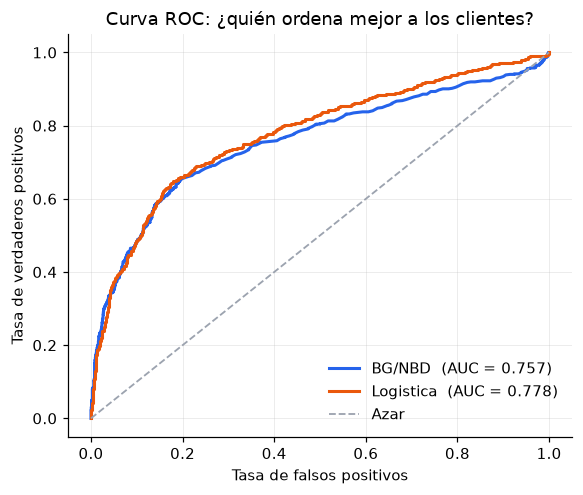

In [6]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))

for nombre, p, color in [("BG/NBD", res.p_bg, C_BG), ("Logistica", res.p_log, C_LOG)]:
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{nombre}  (AUC = {roc_auc_score(y, p):.3f})")

ax.plot([0, 1], [0, 1], "--", color=C_GRIS, lw=1.2, label="Azar")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curva ROC: ¿quién ordena mejor a los clientes?")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

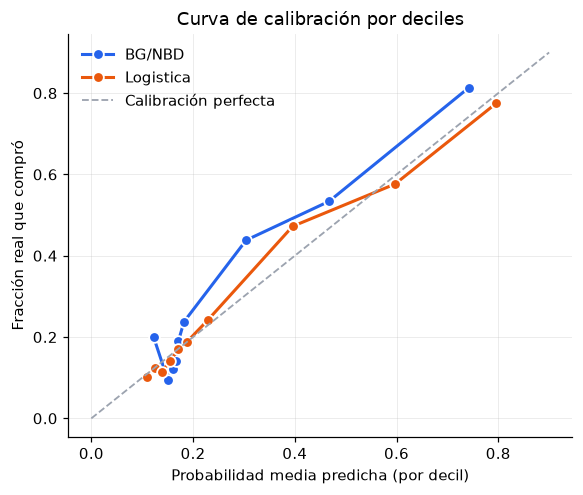

In [7]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))

for nombre, p, color in [("BG/NBD", res.p_bg.values, C_BG), ("Logistica", res.p_log.values, C_LOG)]:
    decil = pd.qcut(p, 10, labels=False, duplicates="drop")
    t = pd.DataFrame({"p": p, "y": y, "d": decil}).groupby("d").agg(pred=("p", "mean"), real=("y", "mean"))
    ax.plot(t.pred, t.real, "o-", color=color, lw=2, ms=7, label=nombre,
            markeredgecolor="white", markeredgewidth=1.2)

ax.plot([0, 0.9], [0, 0.9], "--", color=C_GRIS, lw=1.2, label="Calibración perfecta")
ax.set_xlabel("Probabilidad media predicha (por decil)")
ax.set_ylabel("Fracción real que compró")
ax.set_title("Curva de calibración por deciles")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

In [8]:
# Tabla de calibracion, por si el grafico no basta
for nombre, p in [("BG/NBD", res.p_bg.values), ("Logistica", res.p_log.values)]:
    decil = pd.qcut(p, 10, labels=False, duplicates="drop")
    t = (pd.DataFrame({"p": p, "y": y, "d": decil}).groupby("d")
         .agg(predicho=("p", "mean"), real=("y", "mean"), n=("y", "size")))
    print(f"--- {nombre} ---")
    print(t.round(3).to_string(), "\n")

--- BG/NBD ---
   predicho   real    n
d                      
0     0.123  0.199  241
1     0.150  0.095  231
2     0.155  0.137  241
3     0.160  0.121  240
4     0.166  0.142  246
5     0.171  0.190  232
6     0.182  0.237  219
7     0.304  0.438  235
8     0.467  0.534  236
9     0.742  0.814  236 

--- Logistica ---
   predicho   real    n
d                      
0     0.109  0.102  236
1     0.124  0.123  236
2     0.139  0.115  235
3     0.154  0.140  236
4     0.171  0.169  236
5     0.187  0.187  235
6     0.229  0.242  236
7     0.396  0.472  235
8     0.597  0.576  236
9     0.796  0.775  236 



In [9]:
modelo = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)).fit(X, y)
lr = modelo.named_steps["logisticregression"]

print("Coeficientes estandarizados (una desviacion estandar de cada variable):")
for nombre, c in sorted(zip(["x", "t_x", "T"], lr.coef_[0]), key=lambda p: -abs(p[1])):
    print(f"  {nombre:4s} {c:+.4f}")
print(f"  intercepto {lr.intercept_[0]:+.4f}")

print("\nCorrelaciones entre predictores:")
print(res[["x", "t_x", "T"]].corr().round(3).to_string())

Coeficientes estandarizados (una desviacion estandar de cada variable):
  t_x  +0.7952
  x    +0.4646
  T    -0.2312
  intercepto -1.0349

Correlaciones entre predictores:
         x    t_x      T
x    1.000  0.663  0.046
t_x  0.663  1.000  0.069
T    0.046  0.069  1.000


### ¿Quién gana?

**La logística, en las dos métricas, pero por muy poco.**

| Modelo | AUC | Brier |
|---|---|---|
| BG/NBD $\mathbb{P}(Z=1)$ | 0.757 | 0.161 |
| **Logística** (out-of-fold) | **0.778** | **0.156** |
| Recencia $t_x$ sola | 0.763 | — |
| Frecuencia $x$ sola | 0.758 | — |
| Predecir la tasa base para todos | — | 0.206 |

La ventaja es de ~0.02 de AUC y ~0.005 de Brier, y es estable: entre las 20 semillas el AUC se mueve
apenas entre 0.775 y 0.779, así que no es ruido de cómo cayeron los *folds*.

El dato incómodo es otro: **la recencia sola (0.763) ya le gana al BG/NBD (0.757)**. Para *ordenar* clientes,
las tres variables crudas contienen prácticamente toda la señal, y el modelo probabilístico no agrega nada.
Esto confirma lo de la Parte 4.

**Donde sí hay una diferencia real es en la calibración.** El BG/NBD subestima de forma sistemática:
predice 0.262 en promedio contra una tasa real de 0.290, y en el decil más alto predice 0.742 cuando
la realidad es 0.814. Los siete deciles de abajo quedan aplastados en una banda estrecha (0.12 a 0.18),
porque todos los clientes con $x = 0$ reciben casi la misma probabilidad.

La logística queda casi encima de la diagonal: su probabilidad media (0.290) coincide con la tasa real
hasta el cuarto decimal. Eso **no es mérito del modelo, es mecánico**: la regresión logística minimiza la
log-pérdida sobre estas mismas etiquetas, y una de sus propiedades es que el promedio de las
probabilidades ajustadas iguala la tasa observada. Dicho de otra forma, está calibrada *para esta ventana*
porque esta ventana es la que vio. Volvemos a esto en 6.2.

### Los coeficientes

Estandarizados (el efecto de moverse una desviación estándar en cada variable):

| Variable | Coeficiente | Lectura |
|---|---|---|
| $t_x$ | **+0.795** | el que más pesa |
| $x$ | +0.465 | un poco más de la mitad que $t_x$ |
| $T$ | −0.231 | el único con signo negativo |
| intercepto | −1.035 | |

- **$t_x$ (+, el más fuerte).** Entre más tarde ocurrió la última compra, más probable es que el cliente
  vuelva a comprar. Es la recencia, y encaja con que sea el mejor predictor individual (AUC 0.763).

- **$x$ (+).** Más compras repetidas en calibración, más probable que compre en el *holdout*. Pesa menos de lo
  que uno esperaría, pero hay que leerlo junto con la correlación: $x$ y $t_x$ están correlacionadas 0.66
  (quien compra mucho casi siempre compró hace poco), así que se reparten el crédito de una misma señal.

- **$T$ (−).** Es el interesante. Controlando por $x$ y $t_x$, un cliente que lleva más tiempo en la base
  tiene un hueco final más largo ($T - t_x$) sin comprar, y eso lo hace ver muerto. La logística está
  reconstruyendo, de forma burda y lineal, la misma idea que en el BG/NBD lleva el cociente
  $\left(\frac{\alpha+T}{\alpha+t_x}\right)^{r+x}$ dentro de $\mathbb{P}(\text{vivo})$.

Los signos son los correctos y la historia es coherente. Pero son tres números fijos ajustados a una ventana
de 39 semanas: no hay nada en ellos que diga qué pasa si la pregunta cambia (6.4), ni de dónde salieron las
etiquetas (6.2).

## 6.2 ¿Fue justa?

**No.** Los dos modelos no vieron la misma información.

### Qué vio cada uno

| | Datos para estimar | ¿Vio el *holdout*? |
|---|---|---|
| **BG/NBD** | transacciones hasta el 30-sep-1997 | **No.** Los parámetros $(r,\alpha,a,b)$ salen solo de la verosimilitud de calibración. Nada posterior al corte. |
| **Logística** | $(x, t_x, T)$ hasta el 30-sep-1997 **+ la etiqueta $Z_i$** | **Sí.** $Z_i$ es "¿compró entre el 1-oct-1997 y el 30-jun-1998?" |

El problema no es que la logística haga trampa con el cliente que evalúa — la validación cruzada
se encarga de eso. El problema es más sutil: **la CV separa clientes, no tiempo.**

En cada *fold*, la logística aprende con $Z_i$ de 4/5 de los clientes, y esas etiquetas describen
el periodo octubre 1997 – junio 1998. Es decir, el modelo ya sabe *cómo se comportó la cohorte en el
periodo que se le está pidiendo pronosticar*: que el 29% compró, que la relación entre recencia y recompra
fue de tal magnitud en esa ventana concreta. El BG/NBD, parado el 30 de septiembre de 1997, no podía saber
nada de eso.

De ahí viene la calibración perfecta de 6.1. No es que la logística modele mejor a los clientes: es que
le dijimos la respuesta agregada.

### ¿Con qué etiquetas podrían haber entrenado en la vida real?

El 30 de septiembre de 1997, las únicas etiquetas disponibles son **de un periodo anterior**. Habría que
partir la calibración en dos:

```
|<---- construir (x, t_x, T) ---->|<---- observar la etiqueta ---->|<---- holdout real ---->|
1-ene-1997                   1-jul-1997                      30-sep-1997              30-jun-1998
```

Features con los datos hasta una fecha de corte anterior, etiqueta = "¿compró entre esa fecha de corte y
el 30 de septiembre?", y recién entonces aplicar el modelo entrenado a los $(x, t_x, T)$ del 30 de septiembre.
Eso es exactamente lo que construimos en **6.3**.

### Relación con la fuga de la tarea de series de tiempo

Es el mismo error con otro disfraz: **usar información que en el momento de pronosticar todavía no existía**
(*look-ahead bias*).

En la tarea de series de tiempo la fuga aparecía al estandarizar la serie completa, o al escoger el modelo
mirando el periodo de prueba, antes de partir en entrenamiento y prueba — el modelo "sabía" algo del futuro
sin que se notara en el código. Aquí la fuga no está en el preprocesamiento sino **en la etiqueta misma**:
$Z_i$ *es* el futuro.

Y es más difícil de ver, porque todo parece correcto: hay validación cruzada, hay estratificación, hay
20 semillas, las probabilidades son *out-of-fold*. Toda esa maquinaria protege contra sobreajustarse a
clientes individuales, y ninguna protege contra la fuga temporal. Un *split* que mezcla clientes de un
mismo periodo nunca puede detectarla; hace falta un *split* por tiempo.

Hay una consecuencia práctica que cierra el punto. Los coeficientes de 6.1 están pegados a una ventana de
39 semanas: el $-0.231$ de $T$ solo tiene sentido para ese horizonte. Si el gerente mañana pregunta por
13 semanas en lugar de 39, el BG/NBD solo cambia $\tau$ en la fórmula y sigue funcionando — nunca necesitó
etiquetas. La logística tendría que volver a entrenarse, y para eso necesita etiquetas que, en el momento de
decidir, no existen. Eso es 6.4.

## 6.3 La versión honesta

Repliquemos lo que **sí se podría haber hecho el 30 de septiembre de 1997**: entrenar la logística con
etiquetas de un periodo *anterior* al corte, y recién entonces aplicarla al futuro.

Para un horizonte de $H$ semanas:

```
|<-- construir (x, t_x, T) -->|<-- etiqueta: ¿compró? -->|<-- aplicar y evaluar: ¿compró? -->|
1-ene-1997              corte_tr                   30-sep-1997                   30-sep + H semanas
                        \________ H semanas _______/                 \______ H semanas ______/
                                ENTRENAMIENTO                              EVALUACIÓN
```

- **$H = 13$:** características al 1-jul-1997, etiqueta del 2-jul al 30-sep. Se predicen las primeras 13 semanas del *holdout*.
- **$H = 26$:** características al 1-abr-1997, etiqueta del 2-abr al 30-sep. Se predicen las primeras 26 semanas del *holdout*.

El competidor, el BG/NBD, **no se reentrena**: conserva los mismos $(r,\alpha,a,b)$ de la Parte 2 y solo
cambia $\tau$ en la fórmula de 4.3.

In [10]:
compras = df[["id", "fecha"]].drop_duplicates()      # una compra por cliente-dia
FIN_CAL = pd.Timestamp("1997-09-30")

def resumen(compras, corte):
    '''(x, t_x, T) de cada cliente usando solo los datos hasta 'corte'.'''
    cal = compras[compras.fecha <= corte]
    g = cal.groupby("id").fecha
    o = pd.DataFrame({"primera": g.min(), "ultima": g.max(), "n": g.count()})
    o["x"]   = o.n - 1
    o["t_x"] = (o.ultima - o.primera).dt.days / 7
    o["T"]   = (corte - o.primera).dt.days / 7
    return o[["x", "t_x", "T"]]

def etiqueta(compras, ini, fin, idx):
    '''1 si el cliente compro al menos una vez en (ini, fin].'''
    m = compras[(compras.fecha > ini) & (compras.fecha <= fin)]
    return m.groupby("id").size().reindex(idx).fillna(0).gt(0).astype(int).values

def ventana_honesta(H):
    '''Entrena con un periodo anterior al corte y evalua en el holdout.'''
    dias     = H * 7
    corte_tr = FIN_CAL - pd.Timedelta(days=dias)
    fin_tr   = corte_tr + pd.Timedelta(days=dias)
    fin_ev   = FIN_CAL + pd.Timedelta(days=dias)

    tr, ev = resumen(compras, corte_tr), resumen(compras, FIN_CAL)
    y_tr   = etiqueta(compras, corte_tr, fin_tr, tr.index)
    y_ev   = etiqueta(compras, FIN_CAL, fin_ev, ev.index)

    modelo = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000))
    modelo.fit(tr[["x", "t_x", "T"]].values, y_tr)

    return dict(H=H, corte_tr=corte_tr, fin_tr=fin_tr, fin_ev=fin_ev,
                tr=tr, ev=ev, y_tr=y_tr, y_ev=y_ev, modelo=modelo,
                p_log=modelo.predict_proba(ev[["x", "t_x", "T"]].values)[:, 1],
                p_bg=p_z1(ev.x, ev.t_x, ev["T"], float(H)))

v13, v26 = ventana_honesta(13), ventana_honesta(26)

for v in (v13, v26):
    print(f"H = {v['H']:>2} semanas")
    print(f"  entrenar: (x,t_x,T) al {v['corte_tr'].date()}   etiqueta ({v['corte_tr'].date()}, {v['fin_tr'].date()}]"
          f"   tasa base {v['y_tr'].mean():.4f}")
    print(f"  evaluar : (x,t_x,T) al {FIN_CAL.date()}   etiqueta ({FIN_CAL.date()}, {v['fin_ev'].date()}]"
          f"   tasa base {v['y_ev'].mean():.4f}\n")

H = 13 semanas
  entrenar: (x,t_x,T) al 1997-07-01   etiqueta (1997-07-01, 1997-09-30]   tasa base 0.1744
  evaluar : (x,t_x,T) al 1997-09-30   etiqueta (1997-09-30, 1997-12-30]   tasa base 0.1706

H = 26 semanas
  entrenar: (x,t_x,T) al 1997-04-01   etiqueta (1997-04-01, 1997-09-30]   tasa base 0.3076
  evaluar : (x,t_x,T) al 1997-09-30   etiqueta (1997-09-30, 1998-03-31]   tasa base 0.2512



In [11]:
filas = []
for v in (v13, v26):
    H, y_ev, ev = v["H"], v["y_ev"], v["ev"]
    base = np.full(len(y_ev), y_ev.mean())
    filas += [
        (H, f"BG/NBD  tau={H}",      roc_auc_score(y_ev, v["p_bg"]),  brier_score_loss(y_ev, v["p_bg"]),  v["p_bg"].mean(),  y_ev.mean()),
        (H, "Logistica honesta",     roc_auc_score(y_ev, v["p_log"]), brier_score_loss(y_ev, v["p_log"]), v["p_log"].mean(), y_ev.mean()),
        (H, "Recencia t_x sola",     roc_auc_score(y_ev, ev.t_x),     np.nan,                             np.nan,            y_ev.mean()),
        (H, "Predecir la tasa base", np.nan,                          brier_score_loss(y_ev, base),       y_ev.mean(),       y_ev.mean()),
    ]

comp = pd.DataFrame(filas, columns=["H", "Modelo", "AUC", "Brier", "Prob. media", "Tasa real"])
print(comp.to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4f}"))

 H                Modelo    AUC  Brier  Prob. media  Tasa real
13        BG/NBD  tau=13 0.7844 0.1102       0.1538     0.1706
13     Logistica honesta 0.7921 0.1124       0.1377     0.1706
13     Recencia t_x sola 0.7745      -            -     0.1706
13 Predecir la tasa base      - 0.1415       0.1706     0.1706
26        BG/NBD  tau=26 0.7615 0.1475       0.2204     0.2512
26     Logistica honesta 0.7849 0.1559       0.2003     0.2512
26     Recencia t_x sola 0.7626      -            -     0.2512
26 Predecir la tasa base      - 0.1881       0.2512     0.2512


In [12]:
print("Coeficientes estandarizados: ¿cambia la historia al ser honestos?\n")
print(f"{'Version':<34}{'x':>9}{'t_x':>9}{'T':>9}{'intercepto':>13}")

modelo_ingenuo = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)).fit(X, y)
lr0 = modelo_ingenuo.named_steps["logisticregression"]
print(f"{'6.1 ingenua (etiquetas futuras)':<34}" + "".join(f"{c:>+9.4f}" for c in lr0.coef_[0]) + f"{lr0.intercept_[0]:>+13.4f}")

for v in (v13, v26):
    lr = v["modelo"].named_steps["logisticregression"]
    print(f"{'6.3 honesta, H=' + str(v['H']) + ' semanas':<34}" + "".join(f"{c:>+9.4f}" for c in lr.coef_[0]) + f"{lr.intercept_[0]:>+13.4f}")

Coeficientes estandarizados: ¿cambia la historia al ser honestos?

Version                                   x      t_x        T   intercepto
6.1 ingenua (etiquetas futuras)     +0.4646  +0.7952  -0.2312      -1.0349
6.3 honesta, H=13 semanas           +0.5458  +0.4591  -0.2442      -1.7610
6.3 honesta, H=26 semanas           +0.5968  +0.2666  -0.3297      -0.8519


### ¿Qué le estamos pidiendo a la logística? El rango de $T$

In [13]:
print(f"{'':<22}{'T entrenamiento':>22}{'T evaluacion':>22}{'traslape':>12}")
for v in (v13, v26):
    a0, a1 = v["tr"]["T"].min(), v["tr"]["T"].max()
    b0, b1 = v["ev"]["T"].min(), v["ev"]["T"].max()
    tras = max(0.0, min(a1, b1) - max(a0, b0))
    print(f"{'H = ' + str(v['H']) + ' semanas':<22}{f'[{a0:.1f}, {a1:.1f}]':>22}{f'[{b0:.1f}, {b1:.1f}]':>22}{tras:>11.1f}s")

print("\nEn desviaciones estandar del entrenamiento (asi es como la logistica ve a T):")
for v in (v13, v26):
    sc = v["modelo"].named_steps["standardscaler"]
    mu, sd = sc.mean_[2], sc.scale_[2]
    z = (v["ev"]["T"].values - mu) / sd
    print(f"  H = {v['H']:>2}: T de evaluacion cae entre z = {z.min():+.1f} y z = {z.max():+.1f}")

                             T entrenamiento          T evaluacion    traslape
H = 13 semanas                  [14.0, 25.9]          [27.0, 38.9]        0.0s
H = 26 semanas                   [1.0, 12.9]          [27.0, 38.9]        0.0s

En desviaciones estandar del entrenamiento (asi es como la logistica ve a T):
  H = 13: T de evaluacion cae entre z = +2.2 y z = +5.8
  H = 26: T de evaluacion cae entre z = +6.1 y z = +9.7


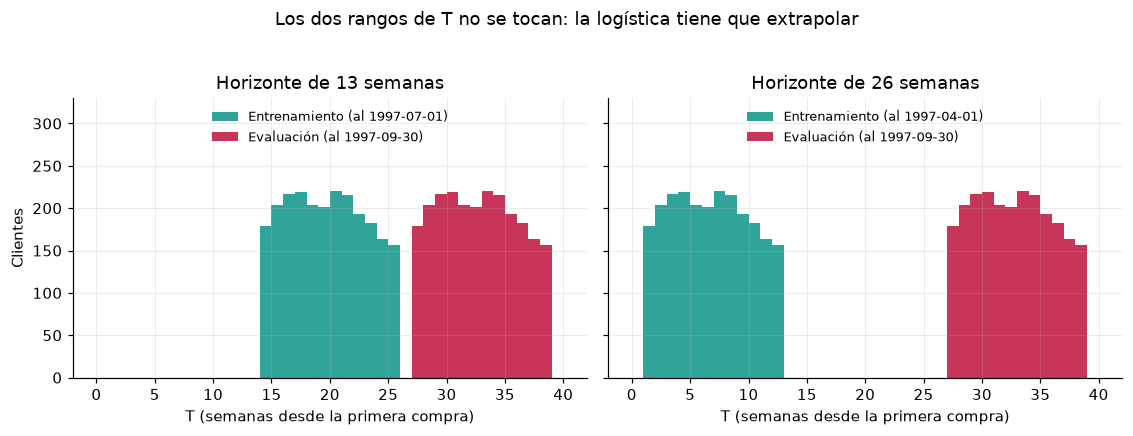

In [14]:
C_TR, C_EV = "#0d9488", "#be123c"       # periodo de entrenamiento vs periodo de evaluacion
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.8), sharey=True)

for ax, v in zip(axes, (v13, v26)):
    bins = np.linspace(0, 40, 41)
    ax.hist(v["tr"]["T"], bins=bins, color=C_TR, alpha=0.85, label=f"Entrenamiento (al {v['corte_tr'].date()})")
    ax.hist(v["ev"]["T"], bins=bins, color=C_EV, alpha=0.85, label="Evaluación (al 1997-09-30)")
    ax.set_ylim(0, 330)
    ax.set_title(f"Horizonte de {v['H']} semanas")
    ax.set_xlabel("T (semanas desde la primera compra)")
    ax.legend(frameon=False, fontsize=8.5, loc="upper center")

axes[0].set_ylabel("Clientes")
fig.suptitle("Los dos rangos de T no se tocan: la logística tiene que extrapolar", y=1.03)
plt.tight_layout(); plt.show()

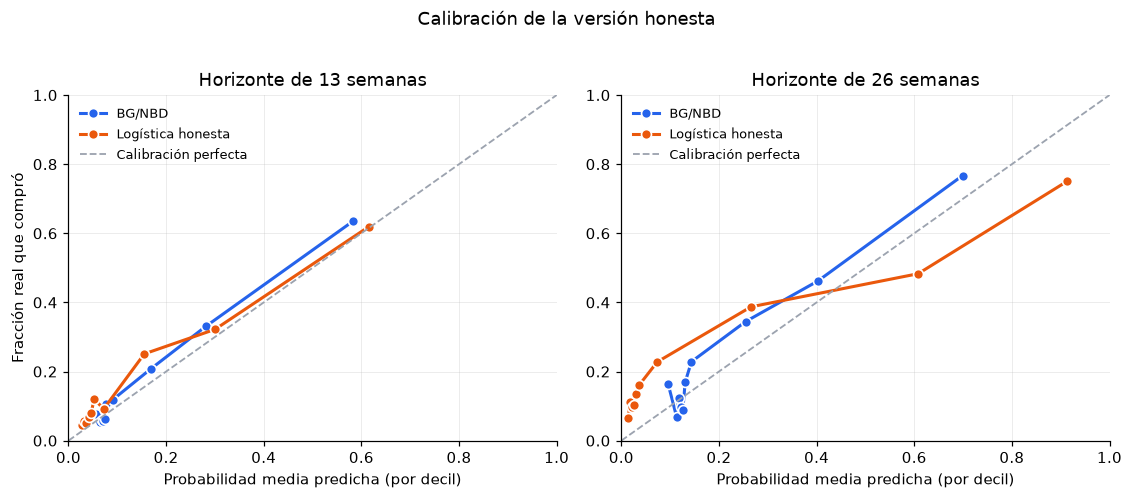

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.4))

for ax, v in zip(axes, (v13, v26)):
    y_ev = v["y_ev"]
    for nombre, p, color in [("BG/NBD", v["p_bg"], C_BG), ("Logística honesta", v["p_log"], C_LOG)]:
        p = np.asarray(p)
        d = pd.qcut(p, 10, labels=False, duplicates="drop")
        t = pd.DataFrame({"p": p, "y": y_ev, "d": d}).groupby("d").agg(pred=("p", "mean"), real=("y", "mean"))
        ax.plot(t.pred, t.real, "o-", color=color, lw=2, ms=6.5, label=nombre,
                markeredgecolor="white", markeredgewidth=1.1)
    lim = 1.0
    ax.plot([0, lim], [0, lim], "--", color=C_GRIS, lw=1.2, label="Calibración perfecta")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(f"Horizonte de {v['H']} semanas")
    ax.set_xlabel("Probabilidad media predicha (por decil)")
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")

axes[0].set_ylabel("Fracción real que compró")
fig.suptitle("Calibración de la versión honesta", y=1.02)
plt.tight_layout(); plt.show()

### Lectura de 6.3

#### Los resultados

| $H$ | Modelo | AUC | Brier | Prob. media | Tasa real |
|---|---|---|---|---|---|
| 13 | BG/NBD $\tau=13$ | 0.784 | **0.110** | 0.154 | 0.171 |
| 13 | **Logística honesta** | **0.792** | 0.112 | 0.138 | 0.171 |
| 13 | Recencia $t_x$ sola | 0.775 | — | — | 0.171 |
| 13 | Predecir la tasa base | — | 0.142 | 0.171 | 0.171 |
| 26 | BG/NBD $\tau=26$ | 0.762 | **0.148** | 0.220 | 0.251 |
| 26 | **Logística honesta** | **0.785** | 0.156 | 0.200 | 0.251 |
| 26 | Recencia $t_x$ sola | 0.763 | — | — | 0.251 |
| 26 | Predecir la tasa base | — | 0.188 | 0.251 | 0.251 |

**Se separan las dos preguntas.** En los dos horizontes pasa lo mismo:

- **Ordenar clientes (AUC): gana la logística.** 0.792 vs 0.784 con $H=13$, y 0.785 vs 0.762 con $H=26$.
  La ventaja es incluso mayor que en la comparación ingenua de 6.1, y es real: aquí no hay fuga.

- **Estimar niveles (Brier): gana el BG/NBD.** 0.110 vs 0.112 con $H=13$, y 0.148 vs 0.156 con $H=26$.
  Y la brecha se abre con el horizonte largo.

Los dos modelos subestiman la tasa real, pero la logística subestima más (0.138 vs 0.154 contra 0.171 real
en $H=13$; 0.200 vs 0.220 contra 0.251 en $H=26$). Tiene sentido: la logística aprendió de un trimestre
**anterior** y arrastra su nivel; el BG/NBD no depende de ningún nivel aprendido, calcula la probabilidad
desde la estructura del modelo.

Nota aparte: la recencia sola sigue siendo un rival duro (0.775 y 0.763). El modelo probabilístico sigue
sin ganarle de forma clara en *ordenar*.

#### El problema del rango de $T$

| $H$ | $T$ en entrenamiento | $T$ en evaluación | Traslape |
|---|---|---|---|
| 13 | [14.0, 25.9] | [27.0, 38.9] | **0 semanas** |
| 26 | [1.0, 12.9] | [27.0, 38.9] | **0 semanas** |

**No hay un solo cliente en común entre los dos rangos.** Esto no es un descuido del diseño: es inevitable.
Como la cohorte es cerrada (todos hicieron su primera compra en el primer trimestre de 1997), $T$ crece
junto con el reloj. Para tener etiquetas pasadas hay que retroceder el corte, y retroceder el corte baja
$T$ para todos. Mientras más largo el horizonte, más atrás hay que irse, y más se abre el hueco.

**Entonces, ¿qué le estamos pidiendo a la logística?** Que **extrapole**. Aprendió la relación entre $T$ y
la recompra en un rango donde $T$ valía entre 14 y 26 semanas, y se la estamos aplicando a clientes con
$T$ entre 27 y 39.

Medido en las unidades en las que el modelo trabaja —desviaciones estándar del entrenamiento, porque el
`StandardScaler` se ajustó ahí— los clientes de evaluación caen **completamente fuera** de lo que vio:

| $H$ | $T$ de evaluación, en $z$ del entrenamiento |
|---|---|
| 13 | de $+2.2$ a $+5.8$ |
| 26 | de $+6.1$ a $+9.7$ |

Ni el cliente *más nuevo* del conjunto de evaluación cae dentro del rango de entrenamiento. Con $H=26$ el
desplazamiento es grotesco: hasta 10 desviaciones estándar.

Una regresión logística es lineal en el *logit*: fuera de su rango de entrenamiento no se aplana, sigue
derecho. Por eso la calibración de la versión honesta se rompe justo donde se espera: con $H=26$ el decil
más bajo predice 0.014 cuando la realidad es 0.066 (subestima casi 5 veces), y el decil más alto predice
0.913 cuando la realidad es 0.750. El modelo está **demasiado seguro en ambos extremos**, el síntoma
clásico de extrapolar una recta.

El BG/NBD no tiene este problema porque $T$ no es un predictor con un coeficiente ajustado: entra en la
fórmula como el tiempo que lleva corriendo el proceso de Poisson del cliente. Sigue siendo correcto para
cualquier valor de $T$, dentro o fuera de lo que se vio al estimar.

#### Los coeficientes cambian al ser honestos

| Versión | $x$ | $t_x$ | $T$ |
|---|---|---|---|
| 6.1 ingenua (etiquetas futuras) | +0.465 | **+0.795** | −0.231 |
| 6.3 honesta, $H=13$ | **+0.546** | +0.459 | −0.244 |
| 6.3 honesta, $H=26$ | **+0.597** | +0.267 | −0.330 |

Se voltea la jerarquía. Con las etiquetas futuras mandaba la recencia; al ser honestos manda la frecuencia,
y el peso de $t_x$ se cae a la mitad (y a un tercio con $H=26$). La razón es que al retroceder el corte los
clientes tienen menos historia — con $H=26$, el 78% tiene $x = 0$ y por lo tanto $t_x = 0$, así que la
recencia casi no distingue a nadie y el modelo se recarga en lo poco que varía.

Esto es lo incómodo del asunto: **los coeficientes no son una propiedad de los clientes, son una propiedad
de la ventana con la que se entrenó.** Tres ventanas, tres historias distintas sobre qué variable importa.
El BG/NBD da la misma respuesta siempre, porque sus parámetros describen a los clientes
($\lambda$ y $p$), no a la ventana.

## 6.4 Cambiar la pregunta

El gerente ahora quiere saber **quién compra en las próximas 13 semanas**, no en 39.

- **BG/NBD:** solo cambia $\tau$. Mismos $(r,\alpha,a,b)$, misma fórmula de 4.3, $\tau=39 \to \tau=13$. Nada más.
- **Logística de 6.1:** fue ajustada contra $Z$ = "¿compró en las 39 semanas del *holdout*?". Para responder la
  pregunta nueva habría que **reentrenarla** con etiquetas de 13 semanas... que el 30 de septiembre no existen.
  Volvemos al callejón de 6.2 y 6.3.

Aquí la usamos **tal cual**, que es lo que haría cualquiera con prisa, y miramos qué pasa.

In [16]:
# Reutilizamos lo ya calculado:
#   res.p_log  -> logistica de 6.1 (out-of-fold, etiquetas de 39 semanas)
#   res.p_bg   -> BG/NBD con tau=39
#   v13        -> BG/NBD con tau=13 y la etiqueta real de 13 semanas
assert (res.id.values == v13["ev"].index.values).all()     # mismo orden de clientes

y39, y13 = res.Z.values, v13["y_ev"]
p_log, p_bg39, p_bg13 = res.p_log.values, res.p_bg.values, v13["p_bg"]

print(f"Tasa real a 39 semanas: {y39.mean():.4f}")
print(f"Tasa real a 13 semanas: {y13.mean():.4f}")

filas = [
    ("BG/NBD  tau=39", "39 semanas", p_bg39, y39),
    ("Logistica 6.1",  "39 semanas", p_log,  y39),
    ("BG/NBD  tau=13", "13 semanas", p_bg13, y13),
    ("Logistica 6.1 TAL CUAL", "13 semanas", p_log, y13),
]
t = pd.DataFrame([(n, h, roc_auc_score(yy, p), brier_score_loss(yy, p), p.mean(), yy.mean())
                  for n, h, p, yy in filas],
                 columns=["Modelo", "Pregunta", "AUC", "Brier", "Prob. media", "Tasa real"])
base13 = brier_score_loss(y13, np.full(len(y13), y13.mean()))
print("\n" + t.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nBrier de predecir la tasa base a 13 semanas para todos: {base13:.4f}")

Tasa real a 39 semanas: 0.2902
Tasa real a 13 semanas: 0.1706

                Modelo   Pregunta    AUC  Brier  Prob. media  Tasa real
        BG/NBD  tau=39 39 semanas 0.7569 0.1612       0.2619     0.2902
         Logistica 6.1 39 semanas 0.7776 0.1561       0.2903     0.2902
        BG/NBD  tau=13 13 semanas 0.7844 0.1102       0.1538     0.1706
Logistica 6.1 TAL CUAL 13 semanas 0.7893 0.1287       0.2903     0.1706

Brier de predecir la tasa base a 13 semanas para todos: 0.1415


In [17]:
print(f"Sobrestimacion de la logistica: predice {p_log.mean():.4f} contra una tasa real de "
      f"{y13.mean():.4f}  ->  {p_log.mean()/y13.mean():.2f} veces mas alto\n")

print("Pero el ORDEN casi no cambia:")
print(f"  correlacion de Spearman entre la logistica 6.1 y el BG/NBD tau=13: "
      f"{pd.Series(p_log).corr(pd.Series(p_bg13), method='spearman'):.4f}\n")

print("Consecuencia practica: mandar promocion a todos los clientes con p > 0.5")
print(f"{'':<26}{'marcados':>10}{'esperado':>11}{'real':>9}")
for nombre, p in [("Logistica 6.1 tal cual", p_log), ("BG/NBD tau=13", p_bg13)]:
    sel = p > 0.5
    print(f"{nombre:<26}{sel.sum():>10}{p[sel].mean():>11.3f}{y13[sel].mean():>9.3f}")

Sobrestimacion de la logistica: predice 0.2903 contra una tasa real de 0.1706  ->  1.70 veces mas alto

Pero el ORDEN casi no cambia:
  correlacion de Spearman entre la logistica 6.1 y el BG/NBD tau=13: 0.9286

Consecuencia practica: mandar promocion a todos los clientes con p > 0.5
                            marcados   esperado     real
Logistica 6.1 tal cual           471      0.697    0.465
BG/NBD tau=13                    142      0.682    0.711


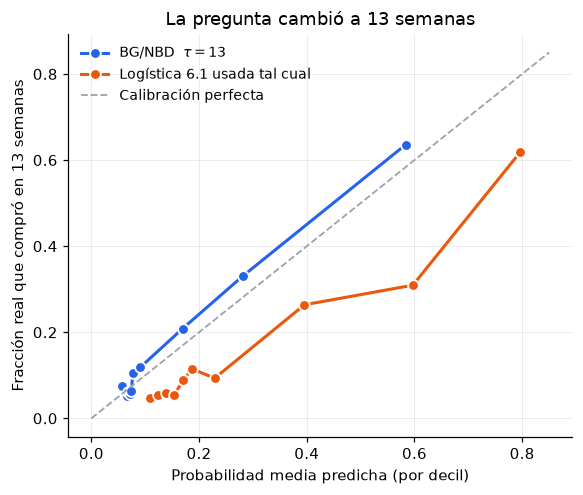

In [18]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))

for nombre, p, color in [("BG/NBD  $\\tau=13$", p_bg13, C_BG),
                         ("Logística 6.1 usada tal cual", p_log, C_LOG)]:
    d = pd.qcut(p, 10, labels=False, duplicates="drop")
    t = pd.DataFrame({"p": p, "y": y13, "d": d}).groupby("d").agg(pred=("p", "mean"), real=("y", "mean"))
    ax.plot(t.pred, t.real, "o-", color=color, lw=2, ms=7, label=nombre,
            markeredgecolor="white", markeredgewidth=1.2)

ax.plot([0, 0.85], [0, 0.85], "--", color=C_GRIS, lw=1.2, label="Calibración perfecta")
ax.set_xlabel("Probabilidad media predicha (por decil)")
ax.set_ylabel("Fracción real que compró en 13 semanas")
ax.set_title("La pregunta cambió a 13 semanas")
ax.legend(loc="upper left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

### ¿Qué pasó?

| Modelo | Pregunta | AUC | Brier | Prob. media | Tasa real |
|---|---|---|---|---|---|
| BG/NBD $\tau=13$ | 13 semanas | 0.784 | **0.110** | 0.154 | 0.171 |
| Logística 6.1 **tal cual** | 13 semanas | **0.789** | 0.129 | **0.290** | 0.171 |
| *(referencia)* predecir la tasa base | 13 semanas | — | 0.142 | 0.171 | 0.171 |

**El orden sobrevive; el nivel se desploma.**

- **Ordenar: no pasó nada.** El AUC de la logística incluso *sube* al cambiar la pregunta (0.778 → 0.789),
  y le gana al BG/NBD. La correlación de Spearman entre la logística de 6.1 y el BG/NBD con $\tau=13$ es
  **0.93**: ordenan casi igual. Tiene sentido — quien es buen candidato a comprar en 39 semanas es, en
  general, buen candidato a comprar en 13. El ranking es casi invariante al horizonte.

- **Los niveles: desastre.** La logística sigue prediciendo 0.290 en promedio, porque es el único número que
  sabe decir; la tasa real a 13 semanas es 0.171. **Sobrestima 1.70 veces.** Su Brier (0.129) apenas le gana
  a la estrategia de no hacer nada y predecir la tasa base para todos (0.142). En la gráfica, toda su curva
  de calibración cae **por debajo** de la diagonal —para cada decil, la fracción que realmente compró es
  menor que la prometida—: el modelo sigue contestando la pregunta de 39 semanas, que ya nadie le hizo.

**Y esto sí le cuesta dinero al gerente.** Si la regla es "mandar promoción a quien tenga $p > 0.5$":

| | Clientes marcados | Tasa esperada | Tasa real |
|---|---|---|---|
| Logística 6.1 tal cual | **471** | 0.697 | **0.465** |
| BG/NBD $\tau=13$ | **142** | 0.682 | **0.711** |

La logística marca **3.3 veces más clientes** y falla por 23 puntos en lo que promete. El BG/NBD acierta
casi exacto. Un presupuesto armado con la logística se dispara, y la tasa de respuesta llega a la mitad de
lo prometido.

### ¿Qué tendrían que hacer con la logística?

Reentrenarla con etiquetas de 13 semanas. Y ahí se cierra el círculo del inciso 6.2: esas etiquetas, el
30 de septiembre, **no existen todavía**. Hay que retroceder el corte, construir las características en una
fecha anterior y usar un periodo pasado de 13 semanas como etiqueta — exactamente el montaje de 6.3, con
el problema de extrapolación en $T$ que vimos ahí. Y habría que repetir todo ese trabajo **cada vez que el
gerente cambie el horizonte**.

El BG/NBD cambia un número en una fórmula. No es que sea más listo: es que modela el *proceso* (cuándo
compra y cuándo muere un cliente) en vez de modelar una *etiqueta* fija. De un proceso se puede leer
cualquier horizonte; de una etiqueta, solo la que se fijó al entrenar.

## 6.5 Veredicto

**En un párrafo.** Usaría la **regresión logística cuando el problema es ordenar clientes dentro de un
horizonte fijo y existan etiquetas de un periodo anterior comparable**: en los tres montajes que probamos
ganó consistentemente en AUC (0.778 vs 0.757 en la comparación ingenua; 0.792 vs 0.784 y 0.785 vs 0.762 en
la versión honesta), es más barata de ajustar y admite cualquier variable extra (canal, categoría,
demografía) que el BG/NBD no sabe recibir — si la pregunta es *"a quién le mando los 500 cupones que tengo"*,
basta con ordenar bien. Usaría el **BG/NBD en todo lo demás**: gana en *Brier* en los dos horizontes
honestos (0.110 vs 0.112 y 0.148 vs 0.156) y sobre todo entrega **niveles creíbles** — su probabilidad media
queda a 0.02 de la tasa real contra 0.03 de la logística, y con el umbral de 0.5 promete 0.68 y entrega 0.71
donde la logística promete 0.70 y entrega 0.47 — que es lo que se necesita para presupuestar, fijar umbrales
o estimar cuántos clientes vale la pena contactar; **domina cuando el horizonte cambia**, porque solo mueve
$\tau$ mientras la logística tendría que reentrenarse con etiquetas que en el momento de decidir no existen
(6.4); es **el único de los dos que responde la pregunta de la Parte 3**, ya que $\mathbb{E}[Y(\tau)]$ da el
número esperado de compras por cliente y se puede sumar para pronosticar el total de la base, mientras que la
logística solo dice "compra o no compra" y no se agrega a nada; y es **el único que funciona sin etiquetas de
un periodo anterior** — en una cohorte nueva, o en el caso de 6.3 donde el rango de $T$ de entrenamiento y el
de aplicación no se traslapaban ni en una semana, la logística extrapola hasta 10 desviaciones estándar y se
rompe, mientras que el BG/NBD solo necesita $(x, t_x, T)$ y parámetros estimados una vez. En resumen: **la
logística ordena, el BG/NBD cuantifica**, y como el ranking resulta casi invariante al horizonte (Spearman
0.93 entre ambos), la ventaja de la logística es justo la parte del problema que menos cuesta resolver — la
recencia sola ya alcanza AUC 0.76 — mientras que lo que la logística no puede dar es lo que el negocio
termina necesitando.

---

### Resumen de los cinco incisos

| | ¿Quién gana? | Por qué |
|---|---|---|
| **6.1** Comparación ingenua | Logística (AUC 0.778 vs 0.757, Brier 0.156 vs 0.161) | Pero su calibración perfecta es mecánica: vio las etiquetas |
| **6.2** ¿Fue justa? | — | No. La CV separa clientes, no tiempo: $Z_i$ *es* el futuro |
| **6.3** Versión honesta | Logística en AUC, BG/NBD en Brier | Y la logística extrapola $T$ fuera de su rango (traslape = 0) |
| **6.4** Cambiar la pregunta | BG/NBD, con claridad | Solo cambia $\tau$; la logística sobrestima 1.70× |
| **6.5** Veredicto | Depende de la pregunta | La logística ordena, el BG/NBD cuantifica |